In [1]:

from google.colab import files
uploaded = files.upload()


Saving myntra_dataset_ByScraping.csv to myntra_dataset_ByScraping.csv


In [2]:

import pandas as pd

# Load the Myntra dataset
df = pd.read_csv("myntra_dataset_ByScraping.csv")

# Display basic information
print("DATASET LOADED SUCCESSFULLY!")
print("Number of rows and columns:", df.shape)

# Display column names
print("\nCOLUMN NAMES:")
print(df.columns.tolist())

# Display first 5 records
print("\nFIRST 5 PRODUCTS:")
display(df.head())


DATASET LOADED SUCCESSFULLY!
Number of rows and columns: (52120, 7)

COLUMN NAMES:
['brand_name', 'pants_description', 'price', 'MRP', 'discount_percent', 'ratings', 'number_of_ratings']

FIRST 5 PRODUCTS:


,brand_name,pants_description,price,MRP,discount_percent,ratings,number_of_ratings
0,WROGN,Men Loose Fit Cotton Jeans,1374.0,2499.0,0.45,4.2,57.0
1,Flying Machine,Men Slim Fit Jeans,1829.0,2999.0,0.39,4.6,5.0
2,Roadster,Men Pure Cotton Jeans,974.0,2499.0,0.61,3.6,1100.0
3,Bene Kleed,Relaxed Fit Denim Jeans,873.0,2299.0,0.62,4.0,4800.0
4,Levis,Men 511 Slim Fit Jeans,1478.0,2899.0,0.49,4.3,264.0


In [3]:

# Check dataset quality

print("DATA TYPES:")
display(df.dtypes)

print("\nMISSING VALUES:")
display(df.isnull().sum())

print("\nDUPLICATE ROWS:")
print(df.duplicated().sum())

print("\nSTATISTICAL SUMMARY:")
display(df.describe())


DATA TYPES:


,0
brand_name,object
pants_description,object
price,float64
MRP,float64
discount_percent,float64
ratings,float64
number_of_ratings,float64



MISSING VALUES:


,0
brand_name,0
pants_description,0
price,0
MRP,0
discount_percent,0
ratings,0
number_of_ratings,0



DUPLICATE ROWS:
17047

STATISTICAL SUMMARY:


,price,MRP,discount_percent,ratings,number_of_ratings
count,52120.000000,52120.000000,52120.000000,52120.000000,52120.000000
mean,1594.515445,3180.398438,1.648256,3.997794,91.568937
std,1495.972325,2201.883218,4.687529,0.420404,433.918513
min,337.000000,499.000000,0.020000,1.000000,5.000000
25%,989.000000,2499.000000,0.400000,3.800000,16.000000
50%,1439.000000,2999.000000,0.500000,4.000000,35.000000
75%,1829.000000,3499.000000,0.630000,4.200000,74.000000
max,54000.000000,72000.000000,64.000000,5.000000,30700.000000


In [4]:

# Investigate discount values
print("DISCOUNT VALUE DISTRIBUTION:")
display(df['discount_percent'].describe())

print("\nDISCOUNT VALUES GREATER THAN 1:")
display(df[df['discount_percent'] > 1][
    ['brand_name', 'price', 'MRP', 'discount_percent']
].head(10))

# Check duplicate records
print("\nEXACT DUPLICATE ROWS:", df.duplicated().sum())

# Check unusual prices
print("\nTOP 10 HIGHEST PRICED PRODUCTS:")
display(df.nlargest(10, 'price')[
    ['brand_name', 'pants_description', 'price', 'MRP']
])

# Compare actual and reported discounts
df['calculated_discount'] = (
    (df['MRP'] - df['price']) / df['MRP'] * 100
)

print("\nDISCOUNT COMPARISON:")
display(df[['price', 'MRP', 'discount_percent',
            'calculated_discount']].head(10))


DISCOUNT VALUE DISTRIBUTION:


,discount_percent
count,52120.000000
mean,1.648256
std,4.687529
min,0.020000
25%,0.400000
50%,0.500000
75%,0.630000
max,64.000000



DISCOUNT VALUES GREATER THAN 1:


,brand_name,price,MRP,discount_percent
32,Mast & Harbour,869.0,2999.0,21.30
52,Mast & Harbour,819.0,2599.0,17.80
91,HIGHLANDER,1099.0,2799.0,17.00
97,HERE&NOW,869.0,2499.0,16.30
101,TURMS,3499.0,4999.0,15.00
123,Thomas Scott,999.0,2599.0,16.00
124,Red Tape,1311.0,6399.0,50.88
132,HERE&NOW,929.0,2599.0,16.70
154,Thomas Scott,819.0,3299.0,24.80
180,Thomas Scott,999.0,3499.0,25.00



EXACT DUPLICATE ROWS: 17047

TOP 10 HIGHEST PRICED PRODUCTS:


,brand_name,pants_description,price,MRP
51228,Jacob Cohen,Men Slim Fit Mid-Rise Jeans,54000.0,72000.0
37202,Jacob Cohen,Men Slim Fit Jeans,53062.0,70750.0
37203,United Colors of Benetton,Men Relaxed Fit Mid-Rise Jeans,53062.0,70750.0
18538,Jacob Cohen,Men Jeans,51750.0,57500.0
18539,True Religion,Slim Fit Mid-Rise Jeans,51750.0,57500.0
37312,Jacob Cohen,Mid-Rise Straight Fit Jeans,44625.0,59500.0
37313,United Colors of Benetton,Men Slim Fit Mid-Rise Jeans,44625.0,59500.0
18505,Tramarossa,Men Slim Fit Mid-Rise Jeans,43875.0,58500.0
25103,Tramarossa,Men Jeans,43650.0,48500.0
25104,United Colors of Benetton,Men Relaxed Fit Mid-Rise Jeans,43650.0,48500.0



DISCOUNT COMPARISON:


,price,MRP,discount_percent,calculated_discount
0,1374.0,2499.0,0.45,45.018007
1,1829.0,2999.0,0.39,39.013004
2,974.0,2499.0,0.61,61.024410
3,873.0,2299.0,0.62,62.026968
4,1478.0,2899.0,0.49,49.016902
5,798.0,1699.0,0.53,53.031195
6,944.0,2099.0,0.55,55.026203
7,1623.0,2799.0,0.42,42.015005
8,839.0,2799.0,0.70,70.025009
9,873.0,2299.0,0.62,62.026968


In [5]:

# Create a cleaned working copy
df_clean = df.copy()

# 1. Remove exact duplicate rows
df_clean = df_clean.drop_duplicates()

# 2. Remove records with invalid prices
df_clean = df_clean[
    (df_clean['price'] > 0) &
    (df_clean['MRP'] > 0) &
    (df_clean['MRP'] >= df_clean['price'])
].copy()

# 3. Recalculate discount percentage
df_clean['calculated_discount'] = (
    (df_clean['MRP'] - df_clean['price'])
    / df_clean['MRP'] * 100
)

# 4. Display cleaning results
print("DATA CLEANING COMPLETED")
print("Original records:", len(df))
print("Cleaned records:", len(df_clean))
print("Records removed:", len(df) - len(df_clean))

print("\nCLEANED DATA PREVIEW:")
display(df_clean.head())

print("\nUPDATED DATA QUALITY:")
display(df_clean.describe())


DATA CLEANING COMPLETED
Original records: 52120
Cleaned records: 35073
Records removed: 17047

CLEANED DATA PREVIEW:


,brand_name,pants_description,price,MRP,discount_percent,ratings,number_of_ratings,calculated_discount
0,WROGN,Men Loose Fit Cotton Jeans,1374.0,2499.0,0.45,4.2,57.0,45.018007
1,Flying Machine,Men Slim Fit Jeans,1829.0,2999.0,0.39,4.6,5.0,39.013004
2,Roadster,Men Pure Cotton Jeans,974.0,2499.0,0.61,3.6,1100.0,61.024410
3,Bene Kleed,Relaxed Fit Denim Jeans,873.0,2299.0,0.62,4.0,4800.0,62.026968
4,Levis,Men 511 Slim Fit Jeans,1478.0,2899.0,0.49,4.3,264.0,49.016902



UPDATED DATA QUALITY:


,price,MRP,discount_percent,ratings,number_of_ratings,calculated_discount
count,35073.000000,35073.000000,35073.000000,35073.000000,35073.000000,35073.000000
mean,1618.151627,3277.913654,2.039860,3.975617,103.707296,51.661208
std,1758.242730,2572.046817,5.446518,0.453471,520.459162,15.956114
min,337.000000,499.000000,0.020000,1.000000,5.000000,2.000488
25%,899.000000,2399.000000,0.400000,3.800000,14.000000,40.011432
50%,1418.000000,2999.000000,0.550000,4.000000,31.000000,54.681248
75%,1829.000000,3699.000000,0.650000,4.200000,75.000000,63.895304
max,54000.000000,72000.000000,64.000000,5.000000,30700.000000,86.135038


In [6]:

# BUSINESS KPI ANALYSIS

print("TOTAL PRODUCTS:", len(df_clean))

print("UNIQUE BRANDS:",
      df_clean['brand_name'].nunique())

print("\nAVERAGE SELLING PRICE:")
print("Rs.", round(df_clean['price'].mean(), 2))

print("\nAVERAGE DISCOUNT:")
print(round(df_clean['calculated_discount'].mean(), 2), "%")

print("\nAVERAGE CUSTOMER RATING:")
print(round(df_clean['ratings'].mean(), 2), "/5")

print("\nTOP 10 BRANDS BY PRODUCT COUNT:")

brand_analysis = (
    df_clean.groupby('brand_name')
    .agg(
        product_count=('brand_name', 'size'),
        avg_price=('price', 'mean'),
        avg_rating=('ratings', 'mean'),
        avg_discount=('calculated_discount', 'mean'),
        total_rating_count=('number_of_ratings', 'sum')
    )
    .sort_values('product_count', ascending=False)
)

display(brand_analysis.head(10).round(2))


TOTAL PRODUCTS: 35073
UNIQUE BRANDS: 417

AVERAGE SELLING PRICE:
Rs. 1618.15

AVERAGE DISCOUNT:
51.66 %

AVERAGE CUSTOMER RATING:
3.98 /5

TOP 10 BRANDS BY PRODUCT COUNT:


,product_count,avg_price,avg_rating,avg_discount,total_rating_count
brand_name,,,,,
United Colors of Benetton,3300,1875.68,4.03,49.57,366608.0
Flying Machine,2576,1768.42,3.98,39.34,275393.0
Roadster,1796,774.61,3.87,67.38,531598.0
SPYKAR,1149,1645.68,4.00,57.19,51715.0
WROGN,1101,1378.74,4.00,48.34,148323.0
U.S. Polo Assn. Denim Co.,850,1818.52,4.10,41.46,52583.0
V-Mart,800,1180.04,3.96,22.77,46815.0
glitchez,784,638.58,3.83,66.47,49674.0
Pepe Jeans,659,2037.34,4.06,49.79,37462.0


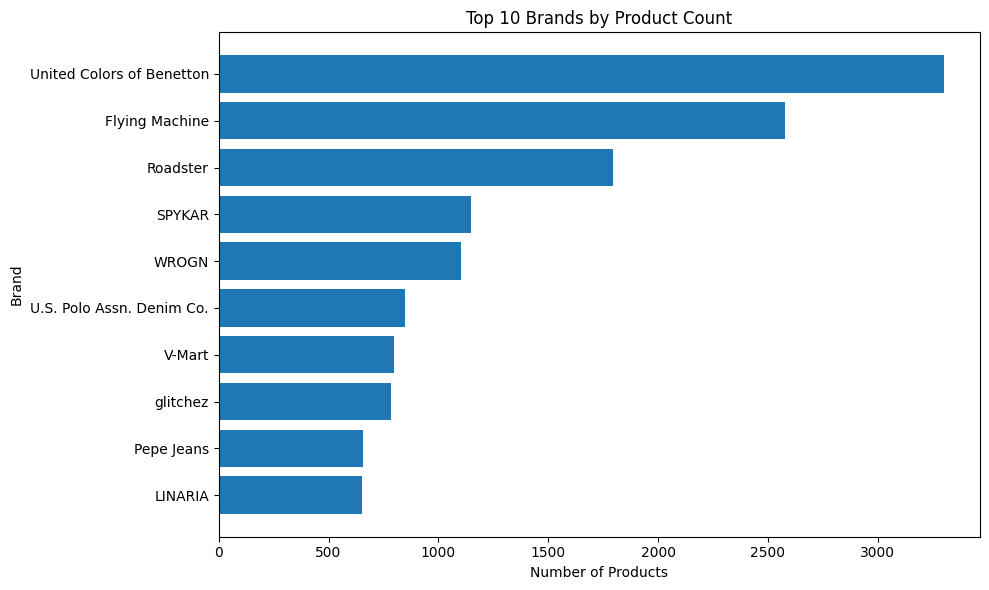

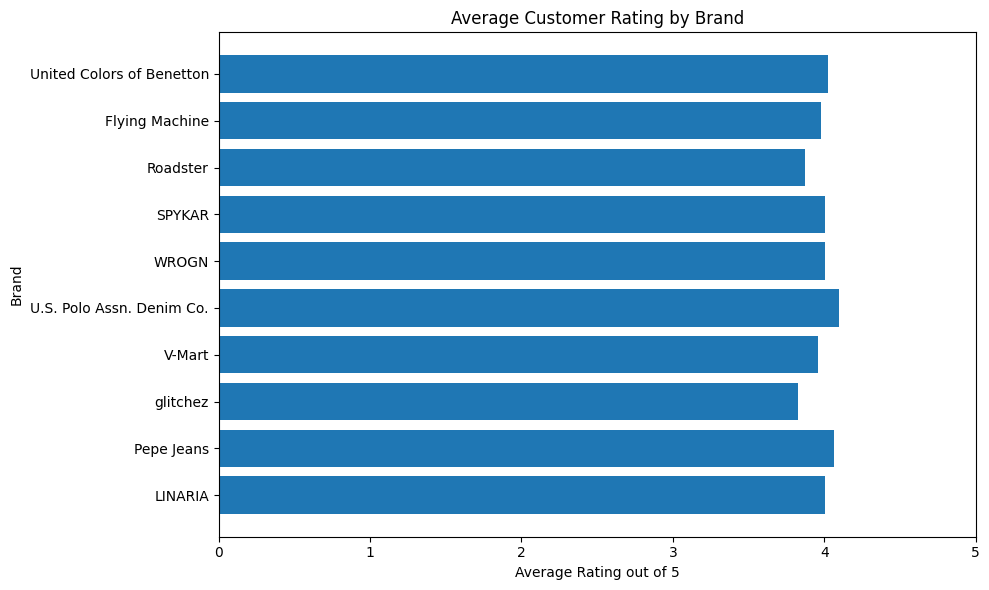

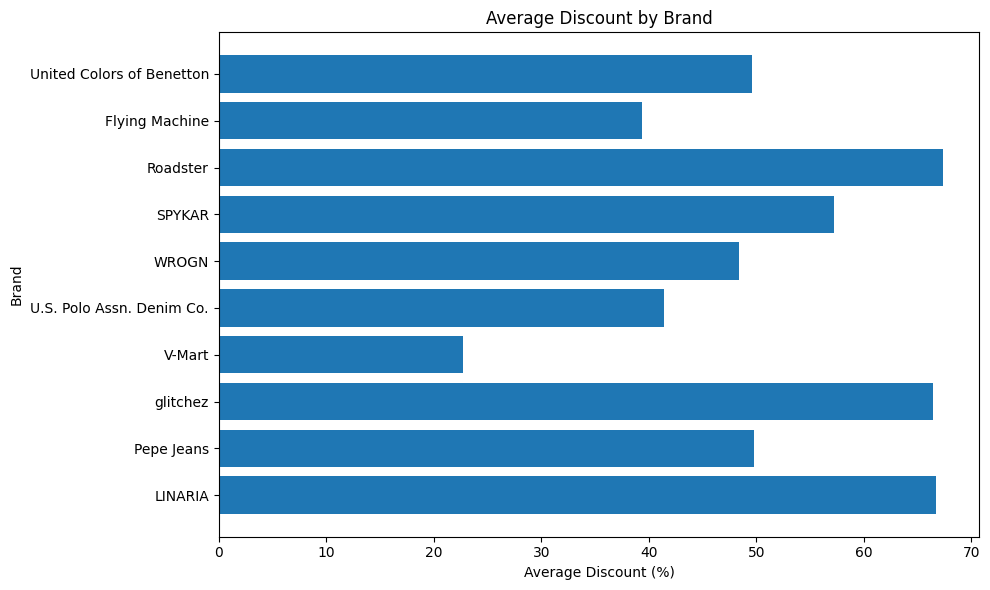

In [7]:

import matplotlib.pyplot as plt

# Select top 10 brands
top_brands = brand_analysis.head(10).sort_values(
    'product_count', ascending=True
)

# Chart 1: Product count by brand
plt.figure(figsize=(10, 6))
plt.barh(top_brands.index, top_brands['product_count'])
plt.title("Top 10 Brands by Product Count")
plt.xlabel("Number of Products")
plt.ylabel("Brand")
plt.tight_layout()
plt.show()

# Chart 2: Average rating by brand
plt.figure(figsize=(10, 6))
plt.barh(top_brands.index, top_brands['avg_rating'])
plt.title("Average Customer Rating by Brand")
plt.xlabel("Average Rating out of 5")
plt.ylabel("Brand")
plt.xlim(0, 5)
plt.tight_layout()
plt.show()

# Chart 3: Average discount by brand
plt.figure(figsize=(10, 6))
plt.barh(top_brands.index, top_brands['avg_discount'])
plt.title("Average Discount by Brand")
plt.xlabel("Average Discount (%)")
plt.ylabel("Brand")
plt.tight_layout()
plt.show()


PRICE SEGMENT ANALYSIS:


,product_count,average_price,average_rating,average_discount,product_share_percent
price_segment,,,,,
Budget,10816,708.09,3.88,63.43,30.84
Mid-range,17461,1516.88,4.01,49.79,49.78
Premium,6796,3326.75,4.04,37.75,19.38


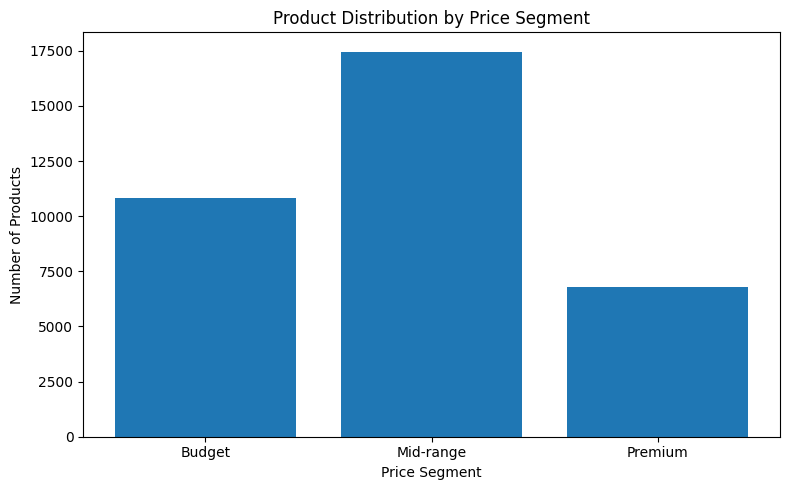

In [8]:

# PRICE SEGMENTATION ANALYSIS

import numpy as np
import matplotlib.pyplot as plt

# Create price categories
df_clean['price_segment'] = pd.cut(
    df_clean['price'],
    bins=[0, 999.99, 1999.99, float('inf')],
    labels=['Budget', 'Mid-range', 'Premium']
)

# Analyse each segment
price_analysis = df_clean.groupby(
    'price_segment', observed=False
).agg(
    product_count=('price', 'count'),
    average_price=('price', 'mean'),
    average_rating=('ratings', 'mean'),
    average_discount=('calculated_discount', 'mean')
)

# Calculate percentage share
price_analysis['product_share_percent'] = (
    price_analysis['product_count']
    / len(df_clean) * 100
)

print("PRICE SEGMENT ANALYSIS:")
display(price_analysis.round(2))

# Visualise product distribution
plt.figure(figsize=(8, 5))
plt.bar(
    price_analysis.index.astype(str),
    price_analysis['product_count']
)
plt.title("Product Distribution by Price Segment")
plt.xlabel("Price Segment")
plt.ylabel("Number of Products")
plt.tight_layout()
plt.show()


In [10]:

# BRAND PERFORMANCE BY PRICE SEGMENT

segment_brand = (
    df_clean.groupby(
        ['price_segment', 'brand_name'],
        observed=True
    )
    .agg(
        product_count=('price', 'size'),
        avg_price=('price', 'mean'),
        avg_rating=('ratings', 'mean'),
        avg_discount=('calculated_discount', 'mean'),
        rating_volume=('number_of_ratings', 'sum')
    )
    .reset_index()
)

# Consider brands with at least 50 products
relevant_brands = segment_brand[
    segment_brand['product_count'] >= 50
].copy()

# Show top 5 brands in each segment by product count
for segment in ['Budget', 'Mid-range', 'Premium']:

    print("\n", "="*45)
    print("PRICE SEGMENT:", segment)
    print("="*45)

    result = relevant_brands[
        relevant_brands['price_segment'] == segment
    ].sort_values('product_count', ascending=False)

    display(result.head(5).round(2))

# Find brands with high ratings but relatively
# low catalogue presence in each segment

for segment in ['Budget', 'Mid-range', 'Premium']:

    result = relevant_brands[
        relevant_brands['price_segment'] == segment
    ].copy()

    if len(result) > 0:
        print("\nPROMISING BRANDS:", segment)

        result = result[
            result['avg_rating'] >= 4.0
        ].sort_values('product_count', ascending=True)

        display(result.head(5).round(2))



PRICE SEGMENT: Budget


,price_segment,brand_name,product_count,avg_price,avg_rating,avg_discount,rating_volume
175,Budget,Roadster,1579,700.01,3.86,68.92,503575.0
234,Budget,glitchez,772,628.07,3.83,66.73,49052.0
210,Budget,United Colors of Benetton,704,692.71,3.91,63.63,164373.0
116,Budget,LINARIA,654,431.91,4.00,66.75,46447.0
137,Budget,Mast & Harbour,430,796.28,3.79,66.93,60532.0



PRICE SEGMENT: Mid-range


,price_segment,brand_name,product_count,avg_price,avg_rating,avg_discount,rating_volume
342,Mid-range,Flying Machine,1928,1618.06,3.99,40.79,207298.0
514,Mid-range,United Colors of Benetton,1705,1546.75,4.04,49.91,125662.0
475,Mid-range,SPYKAR,980,1531.82,4.01,59.04,43010.0
530,Mid-range,WROGN,896,1426.64,4.01,46.27,120906.0
510,Mid-range,U.S. Polo Assn. Denim Co.,611,1591.43,4.13,44.43,32399.0



PRICE SEGMENT: Premium


,price_segment,brand_name,product_count,avg_price,avg_rating,avg_discount,rating_volume
721,Premium,United Colors of Benetton,891,3439.79,4.09,37.82,76573.0
602,Premium,Flying Machine,621,2277.55,3.96,33.76,64745.0
625,Premium,Jack & Jones,333,3016.97,4.03,45.52,18260.0
665,Premium,Pepe Jeans,298,2439.35,4.03,45.78,13483.0
645,Premium,Louis Philippe Jeans,265,2670.38,4.05,29.73,17484.0


... (2 outputs left out)


PROMISING BRANDS: Mid-range


,price_segment,brand_name,product_count,avg_price,avg_rating,avg_discount,rating_volume
307,Mid-range,Canary London,52,1315.25,4.03,66.07,3391.0
391,Mid-range,Koton,61,1771.46,4.09,60.01,3327.0
346,Mid-range,French Connection,62,1516.89,4.16,55.23,3714.0
241,Mid-range,AD By Arvind,63,1463.54,4.01,45.30,2759.0
267,Mid-range,BEAT LONDON by PEPE JEANS,81,1319.26,4.08,51.52,6336.0



PROMISING BRANDS: Premium


,price_segment,brand_name,product_count,avg_price,avg_rating,avg_discount,rating_volume
622,Premium,JADE BLUE,51,2355.31,4.12,33.72,2583.0
728,Premium,VUDU,52,2567.25,4.03,16.31,2436.0
655,Premium,Mufti,53,2123.06,4.00,49.65,2593.0
667,Premium,Peter England Casuals,55,2275.71,4.08,36.52,3458.0
575,Premium,Blackberrys,56,2323.21,4.01,37.90,2878.0


JEANS STYLE DISTRIBUTION:


,product_count,avg_price,avg_rating,avg_discount,share_percent
jeans_style,,,,,
Slim Fit,12006,1744.44,3.99,49.46,34.23
Other / Unspecified,8743,1456.25,3.95,53.84,24.93
Relaxed Fit,3591,1530.33,3.97,53.01,10.24
Skinny Fit,3162,1720.72,4.01,50.94,9.02
Straight Fit,2569,1666.28,3.96,54.80,7.32
Regular Fit,2551,1543.63,3.98,49.63,7.27
Tapered Fit,1434,1651.58,4.00,50.61,4.09
Bootcut,590,1820.96,3.93,52.64,1.68
Loose Fit,427,1124.37,3.89,58.55,1.22



STYLE DISTRIBUTION BY PRICE SEGMENT:


price_segment,Budget,Mid-range,Premium
jeans_style,,,
Bootcut,1.95,1.14,2.65
Loose Fit,2.20,0.97,0.29
Other / Unspecified,32.17,22.64,19.28
Regular Fit,9.08,5.97,7.75
Relaxed Fit,11.30,8.87,12.07
Skinny Fit,4.06,12.10,8.99
Slim Fit,26.90,37.07,38.63
Straight Fit,9.26,6.41,6.58
Tapered Fit,3.09,4.83,3.77


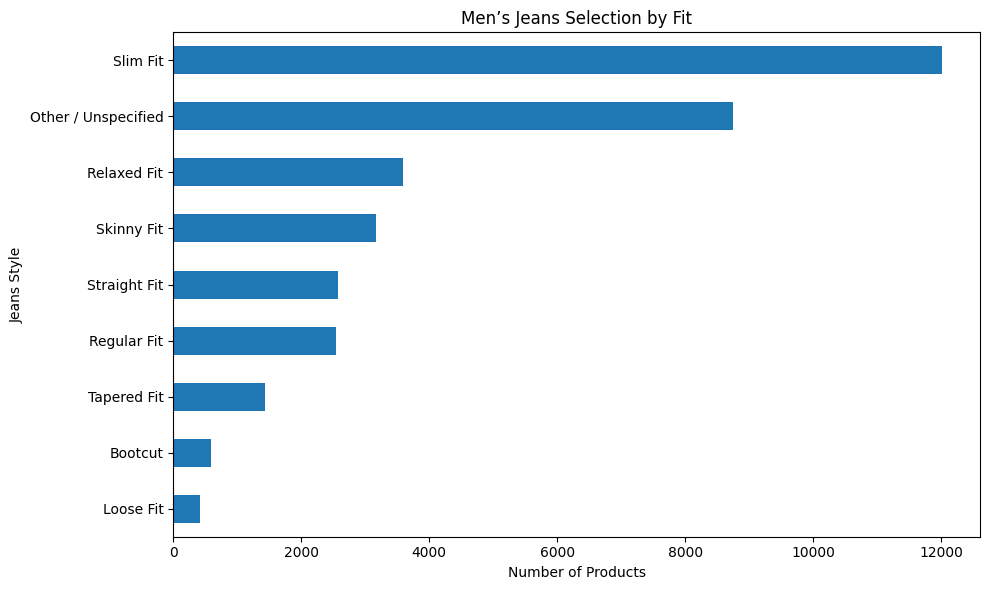

In [11]:

# PRODUCT STYLE ANALYSIS

import re

def identify_style(description):
    text = str(description).lower()

    styles = {
        'Slim Fit': r'\bslim\b',
        'Skinny Fit': r'\bskinny\b',
        'Straight Fit': r'\bstraight\b',
        'Relaxed Fit': r'\brelaxed\b',
        'Loose Fit': r'\bloose\b',
        'Tapered Fit': r'\btapered\b',
        'Bootcut': r'\bbootcut\b',
        'Regular Fit': r'\bregular\b'
    }

    for style, pattern in styles.items():
        if re.search(pattern, text):
            return style

    return 'Other / Unspecified'


df_clean['jeans_style'] = df_clean[
    'pants_description'
].apply(identify_style)

# Overall style distribution
style_analysis = df_clean.groupby(
    'jeans_style'
).agg(
    product_count=('price', 'count'),
    avg_price=('price', 'mean'),
    avg_rating=('ratings', 'mean'),
    avg_discount=('calculated_discount', 'mean')
).sort_values('product_count', ascending=False)

style_analysis['share_percent'] = (
    style_analysis['product_count']
    / len(df_clean) * 100
)

print("JEANS STYLE DISTRIBUTION:")
display(style_analysis.round(2))

# Compare styles across price segments
print("\nSTYLE DISTRIBUTION BY PRICE SEGMENT:")

style_segment = pd.crosstab(
    df_clean['jeans_style'],
    df_clean['price_segment'],
    normalize='columns'
) * 100

display(style_segment.round(2))

# Visualise style distribution
style_analysis['product_count'].sort_values().plot(
    kind='barh',
    figsize=(10, 6),
    title='Men’s Jeans Selection by Fit'
)

plt.xlabel('Number of Products')
plt.ylabel('Jeans Style')
plt.tight_layout()
plt.show()


In [12]:

# INVESTIGATE UNCLASSIFIED PRODUCTS

other_products = df_clean[
    df_clean['jeans_style'] == 'Other / Unspecified'
]

print("UNCLASSIFIED PRODUCTS:", len(other_products))

print("\nMOST COMMON PRODUCT DESCRIPTIONS:")

display(
    other_products['pants_description']
    .value_counts()
    .head(25)
)

print("\nSAMPLE UNCLASSIFIED PRODUCTS:")

display(
    other_products[
        ['brand_name', 'pants_description', 'price', 'ratings']
    ].head(20)
)


UNCLASSIFIED PRODUCTS: 8743

MOST COMMON PRODUCT DESCRIPTIONS:


,count
pants_description,
Men Jeans,1029
Men Mid-Rise Jeans,599
Men Stretchable Jeans,450
Men Anti Fit Mid-Rise Jeans,443
Men Wide Leg Jeans,201
Men Light Fade Jeans,190
Men Mid-Rise Stretchable Jeans,174
Men Mid-Rise Cotton Jeans,142
Men Low-Rise Jeans,132



SAMPLE UNCLASSIFIED PRODUCTS:


,brand_name,pants_description,price,ratings
2,Roadster,Men Pure Cotton Jeans,974.0,3.6
5,HERE&NOW,Men Stretchable Jeans,798.0,4.0
7,WROGN,Men Anti Fit Jeans,1623.0,4.2
8,Bene Kleed,Men Wide Leg Heavy Fade Jeans,839.0,3.6
12,Bene Kleed,Men Wide Leg Jeans,857.0,3.6
14,styzon,Men Jogger Mid-Rise Jeans,899.0,4.1
21,Bene Kleed,Men Mid-Rise Boot Cut Jeans,873.0,4.0
26,Kotty,Men Low-Rise Jeans,519.0,3.7
29,Roadster,Men Wide Leg Jeans,999.0,3.4
31,WROGN,Men Anti Fit Jeans,1399.0,4.1


In [13]:

import numpy as np

# Reclassify previously unclassified products
def classify_style(row):
    desc = str(row['pants_description']).lower()

    if row['jeans_style'] != 'Other / Unspecified':
        return row['jeans_style']

    if 'wide leg' in desc:
        return 'Wide Leg'
    elif 'baggy' in desc:
        return 'Baggy Fit'
    elif 'jogger' in desc:
        return 'Jogger'
    elif 'boot cut' in desc or 'bootcut' in desc:
        return 'Bootcut'
    elif 'cargo' in desc:
        return 'Cargo'
    elif 'boyfriend' in desc:
        return 'Boyfriend Fit'
    elif 'flare' in desc:
        return 'Flared Fit'
    else:
        return 'Other / Unspecified'

df_clean['jeans_style'] = df_clean.apply(
    classify_style, axis=1
)

# Updated distribution
style_analysis = (
    df_clean['jeans_style']
    .value_counts()
    .reset_index()
)

style_analysis.columns = ['Jeans Style', 'Product Count']

style_analysis['Share (%)'] = (
    style_analysis['Product Count']
    / len(df_clean) * 100
).round(2)

print("UPDATED JEANS STYLE DISTRIBUTION")
display(style_analysis)


UPDATED JEANS STYLE DISTRIBUTION


,Jeans Style,Product Count,Share (%)
0,Slim Fit,12006,34.23
1,Other / Unspecified,6425,18.32
2,Relaxed Fit,3591,10.24
3,Skinny Fit,3162,9.02
4,Straight Fit,2569,7.32
5,Regular Fit,2551,7.27
6,Tapered Fit,1434,4.09
7,Baggy Fit,811,2.31
8,Bootcut,594,1.69
9,Wide Leg,498,1.42


JEANS STYLE PERFORMANCE


,product_count,avg_price,avg_rating,avg_discount,rating_volume,market_share_%
jeans_style,,,,,,
Slim Fit,12006,1744.44,3.99,49.46,1471950.0,34.23
Other / Unspecified,6425,1549.07,3.97,52.23,490801.0,18.32
Relaxed Fit,3591,1530.33,3.97,53.01,311518.0,10.24
Skinny Fit,3162,1720.72,4.01,50.94,433273.0,9.02
Straight Fit,2569,1666.28,3.96,54.80,189696.0,7.32
Regular Fit,2551,1543.63,3.98,49.63,260708.0,7.27
Tapered Fit,1434,1651.58,4.00,50.61,198027.0,4.09
Baggy Fit,811,1161.59,3.87,60.65,50624.0,2.31
Bootcut,594,1817.02,3.94,52.63,86118.0,1.69


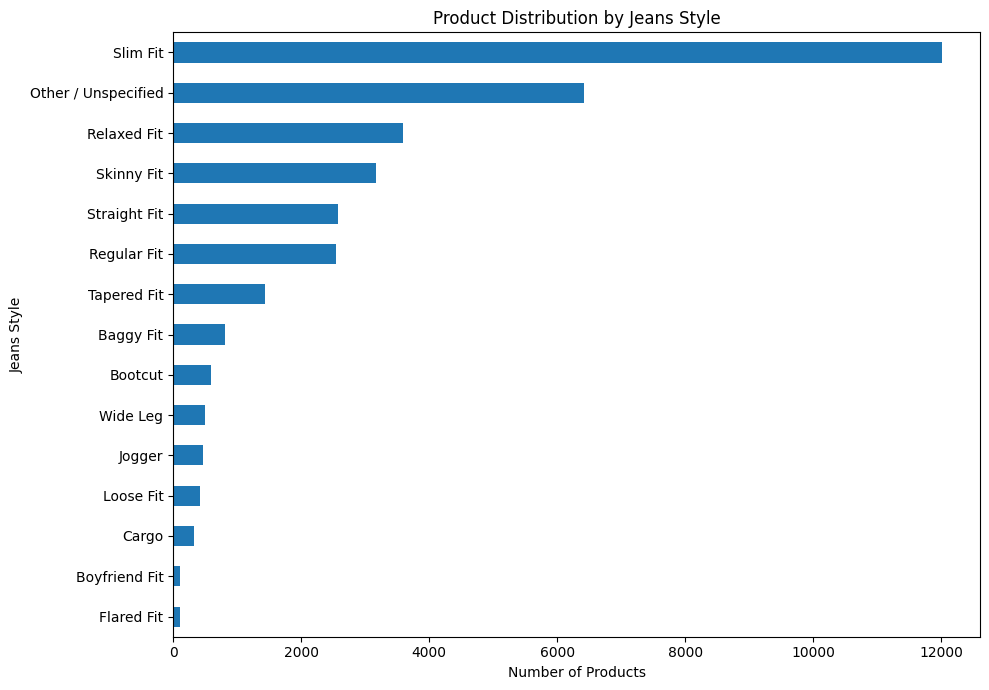

In [14]:

# STYLE PERFORMANCE ANALYSIS

style_performance = (
    df_clean.groupby('jeans_style')
    .agg(
        product_count=('price', 'count'),
        avg_price=('price', 'mean'),
        avg_rating=('ratings', 'mean'),
        avg_discount=('calculated_discount', 'mean'),
        rating_volume=('number_of_ratings', 'sum')
    )
    .round(2)
    .sort_values('product_count', ascending=False)
)

style_performance['market_share_%'] = (
    style_performance['product_count']
    / len(df_clean) * 100
).round(2)

print("JEANS STYLE PERFORMANCE")
display(style_performance)

# VISUALIZATION
import matplotlib.pyplot as plt

style_performance.sort_values(
    'product_count'
)['product_count'].plot(
    kind='barh', figsize=(10, 7)
)

plt.title('Product Distribution by Jeans Style')
plt.xlabel('Number of Products')
plt.ylabel('Jeans Style')
plt.tight_layout()
plt.show()


In [15]:

# BRAND-WISE JEANS STYLE ANALYSIS

brand_style = (
    df_clean.groupby(['jeans_style', 'brand_name'])
    .agg(
        product_count=('price', 'count'),
        avg_price=('price', 'mean'),
        avg_rating=('ratings', 'mean'),
        avg_discount=('calculated_discount', 'mean')
    )
    .reset_index()
)

# Top 3 brands for each style
top_brands_by_style = (
    brand_style.sort_values(
        ['jeans_style', 'product_count'],
        ascending=[True, False]
    )
    .groupby('jeans_style')
    .head(3)
    .round(2)
)

print("TOP 3 BRANDS FOR EACH JEANS STYLE")
display(top_brands_by_style)


TOP 3 BRANDS FOR EACH JEANS STYLE


,jeans_style,brand_name,product_count,avg_price,avg_rating,avg_discount
92,Baggy Fit,glitchez,93,647.18,3.77,67.66
62,Baggy Fit,Roadster,63,766.63,3.74,71.28
69,Baggy Fit,Snitch,54,1640.94,4.03,47.01
159,Bootcut,WAIMEA,69,3396.10,3.97,50.88
142,Bootcut,Roadster,57,784.98,3.81,69.20
144,Bootcut,Snitch,38,2046.21,4.02,45.26
168,Boyfriend Fit,LINARIA,29,509.90,3.77,60.75
176,Boyfriend Fit,SZN,19,510.79,3.82,60.68
169,Boyfriend Fit,MaverIQ,10,482.60,4.01,62.85
259,Cargo,WROGN,49,1535.90,4.12,46.12


In [16]:

# FINAL BUSINESS INSIGHTS

print("=" * 55)
print("MYNTRA MEN'S JEANS CATEGORY - FINAL INSIGHTS")
print("=" * 55)

print("\n1. MOST POPULAR JEANS STYLES")
display(style_performance[
    ['product_count', 'avg_price', 'avg_rating', 'avg_discount']
].head(5))

print("\n2. HIGHEST RATED JEANS STYLES")
display(
    style_performance.sort_values(
        'avg_rating', ascending=False
    ).head(5)
)

print("\n3. HIGHEST DISCOUNT STYLES")
display(
    style_performance.sort_values(
        'avg_discount', ascending=False
    ).head(5)
)

print("\n4. TOP 10 BRANDS OVERALL")
display(
    df_clean.groupby('brand_name')
    .agg(
        products=('price', 'count'),
        avg_price=('price', 'mean'),
        avg_rating=('ratings', 'mean')
    )
    .sort_values('products', ascending=False)
    .head(10).round(2)
)

print("\n5. FINAL DATASET SUMMARY")
print("Total products:", len(df_clean))
print("Unique brands:", df_clean['brand_name'].nunique())
print("Jeans styles:", df_clean['jeans_style'].nunique())
print("Average price: Rs.", round(df_clean['price'].mean(), 2))
print("Average rating:", round(df_clean['ratings'].mean(), 2))


MYNTRA MEN'S JEANS CATEGORY - FINAL INSIGHTS

1. MOST POPULAR JEANS STYLES


,product_count,avg_price,avg_rating,avg_discount
jeans_style,,,,
Slim Fit,12006,1744.44,3.99,49.46
Other / Unspecified,6425,1549.07,3.97,52.23
Relaxed Fit,3591,1530.33,3.97,53.01
Skinny Fit,3162,1720.72,4.01,50.94
Straight Fit,2569,1666.28,3.96,54.80



2. HIGHEST RATED JEANS STYLES


,product_count,avg_price,avg_rating,avg_discount,rating_volume,market_share_%
jeans_style,,,,,,
Skinny Fit,3162,1720.72,4.01,50.94,433273.0,9.02
Tapered Fit,1434,1651.58,4.00,50.61,198027.0,4.09
Slim Fit,12006,1744.44,3.99,49.46,1471950.0,34.23
Cargo,330,1302.19,3.99,55.01,28108.0,0.94
Regular Fit,2551,1543.63,3.98,49.63,260708.0,7.27



3. HIGHEST DISCOUNT STYLES


,product_count,avg_price,avg_rating,avg_discount,rating_volume,market_share_%
jeans_style,,,,,,
Baggy Fit,811,1161.59,3.87,60.65,50624.0,2.31
Flared Fit,100,1497.49,3.84,59.05,5349.0,0.29
Boyfriend Fit,112,766.08,3.83,58.70,8136.0,0.32
Loose Fit,427,1124.37,3.89,58.55,23684.0,1.22
Wide Leg,498,1342.50,3.81,58.20,27472.0,1.42



4. TOP 10 BRANDS OVERALL


,products,avg_price,avg_rating
brand_name,,,
United Colors of Benetton,3300,1875.68,4.03
Flying Machine,2576,1768.42,3.98
Roadster,1796,774.61,3.87
SPYKAR,1149,1645.68,4.00
WROGN,1101,1378.74,4.00
U.S. Polo Assn. Denim Co.,850,1818.52,4.10
V-Mart,800,1180.04,3.96
glitchez,784,638.58,3.83
Pepe Jeans,659,2037.34,4.06



5. FINAL DATASET SUMMARY
Total products: 35073
Unique brands: 417
Jeans styles: 15
Average price: Rs. 1618.15
Average rating: 3.98


MYNTRA JEANS - RELATIONSHIP ANALYSIS

PEARSON CORRELATION:
                     price  ratings  calculated_discount
price                1.000    0.087               -0.333
ratings              0.087    1.000               -0.097
calculated_discount -0.333   -0.097                1.000

SPEARMAN CORRELATION:
                     price  ratings  calculated_discount
price                1.000    0.173               -0.689
ratings              0.173    1.000               -0.131
calculated_discount -0.689   -0.131                1.000


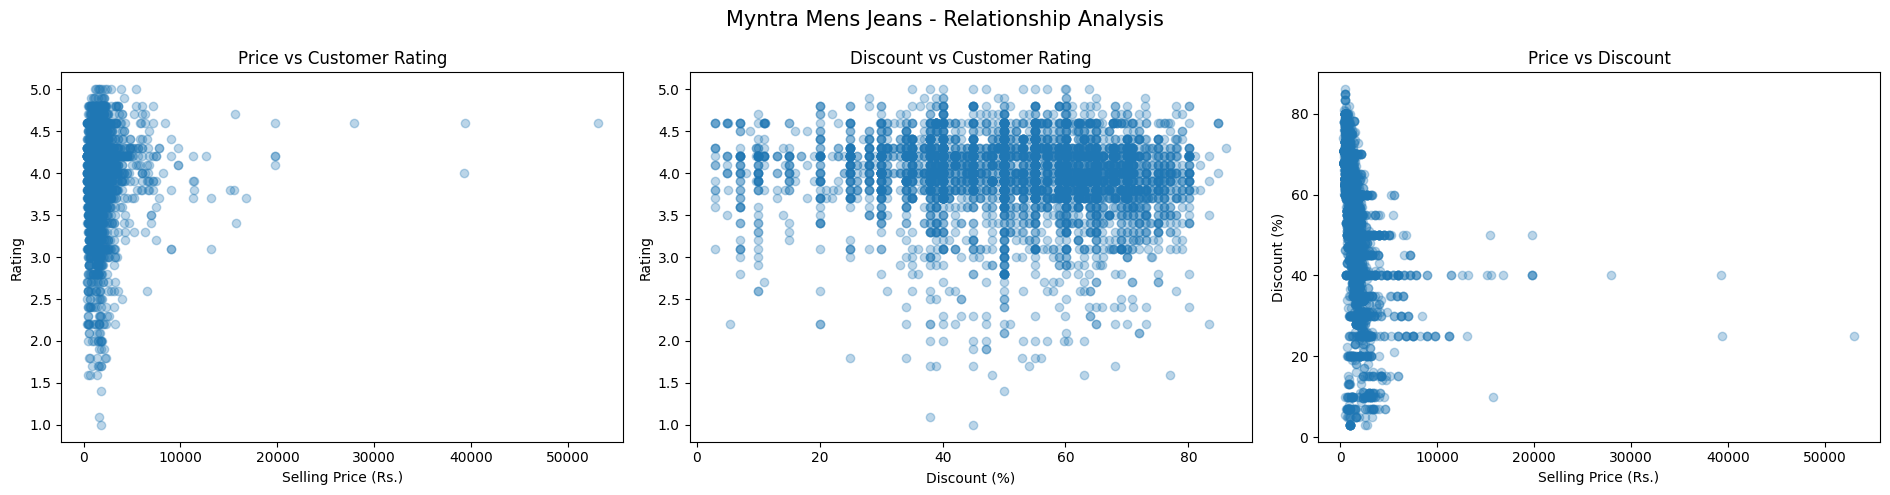


AVERAGE CUSTOMER RATING BY DISCOUNT GROUP:
                count  mean
discount_group             
0-30%            2891  4.04
30-50%          10314  4.01
50-70%          17750  3.96
70-100%          4118  3.88


In [18]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Select relevant columns
analysis_df = df_clean[
    ['price', 'ratings', 'calculated_discount', 'number_of_ratings']
].copy()

# Convert columns to numeric
for col in analysis_df.columns:
    analysis_df[col] = pd.to_numeric(
        analysis_df[col], errors='coerce'
    )

analysis_df = analysis_df.dropna()

print("=" * 55)
print("MYNTRA JEANS - RELATIONSHIP ANALYSIS")
print("=" * 55)

# Pearson correlation
print("\nPEARSON CORRELATION:")
print(
    analysis_df[
        ['price', 'ratings', 'calculated_discount']
    ].corr().round(3)
)

# Spearman correlation
print("\nSPEARMAN CORRELATION:")
print(
    analysis_df[
        ['price', 'ratings', 'calculated_discount']
    ].corr(method='spearman').round(3)
)

# Sample for visualization
plot_df = analysis_df.sample(
    n=min(5000, len(analysis_df)),
    random_state=42
)

# Create charts
fig, axes = plt.subplots(1, 3, figsize=(19, 5))

axes[0].scatter(
    plot_df['price'], plot_df['ratings'], alpha=0.3
)
axes[0].set_title('Price vs Customer Rating')
axes[0].set_xlabel('Selling Price (Rs.)')
axes[0].set_ylabel('Rating')

axes[1].scatter(
    plot_df['calculated_discount'],
    plot_df['ratings'], alpha=0.3
)
axes[1].set_title('Discount vs Customer Rating')
axes[1].set_xlabel('Discount (%)')
axes[1].set_ylabel('Rating')

axes[2].scatter(
    plot_df['price'],
    plot_df['calculated_discount'], alpha=0.3
)
axes[2].set_title('Price vs Discount')
axes[2].set_xlabel('Selling Price (Rs.)')
axes[2].set_ylabel('Discount (%)')

plt.suptitle(
    'Myntra Mens Jeans - Relationship Analysis',
    fontsize=15
)

plt.tight_layout()
plt.show()

# Discount category analysis
analysis_df['discount_group'] = pd.cut(
    analysis_df['calculated_discount'],
    bins=[0, 30, 50, 70, 100],
    labels=['0-30%', '30-50%', '50-70%', '70-100%']
)

print("\nAVERAGE CUSTOMER RATING BY DISCOUNT GROUP:")

print(
    analysis_df.groupby(
        'discount_group',
        observed=False
    )['ratings'].agg(['count', 'mean']).round(2)
)


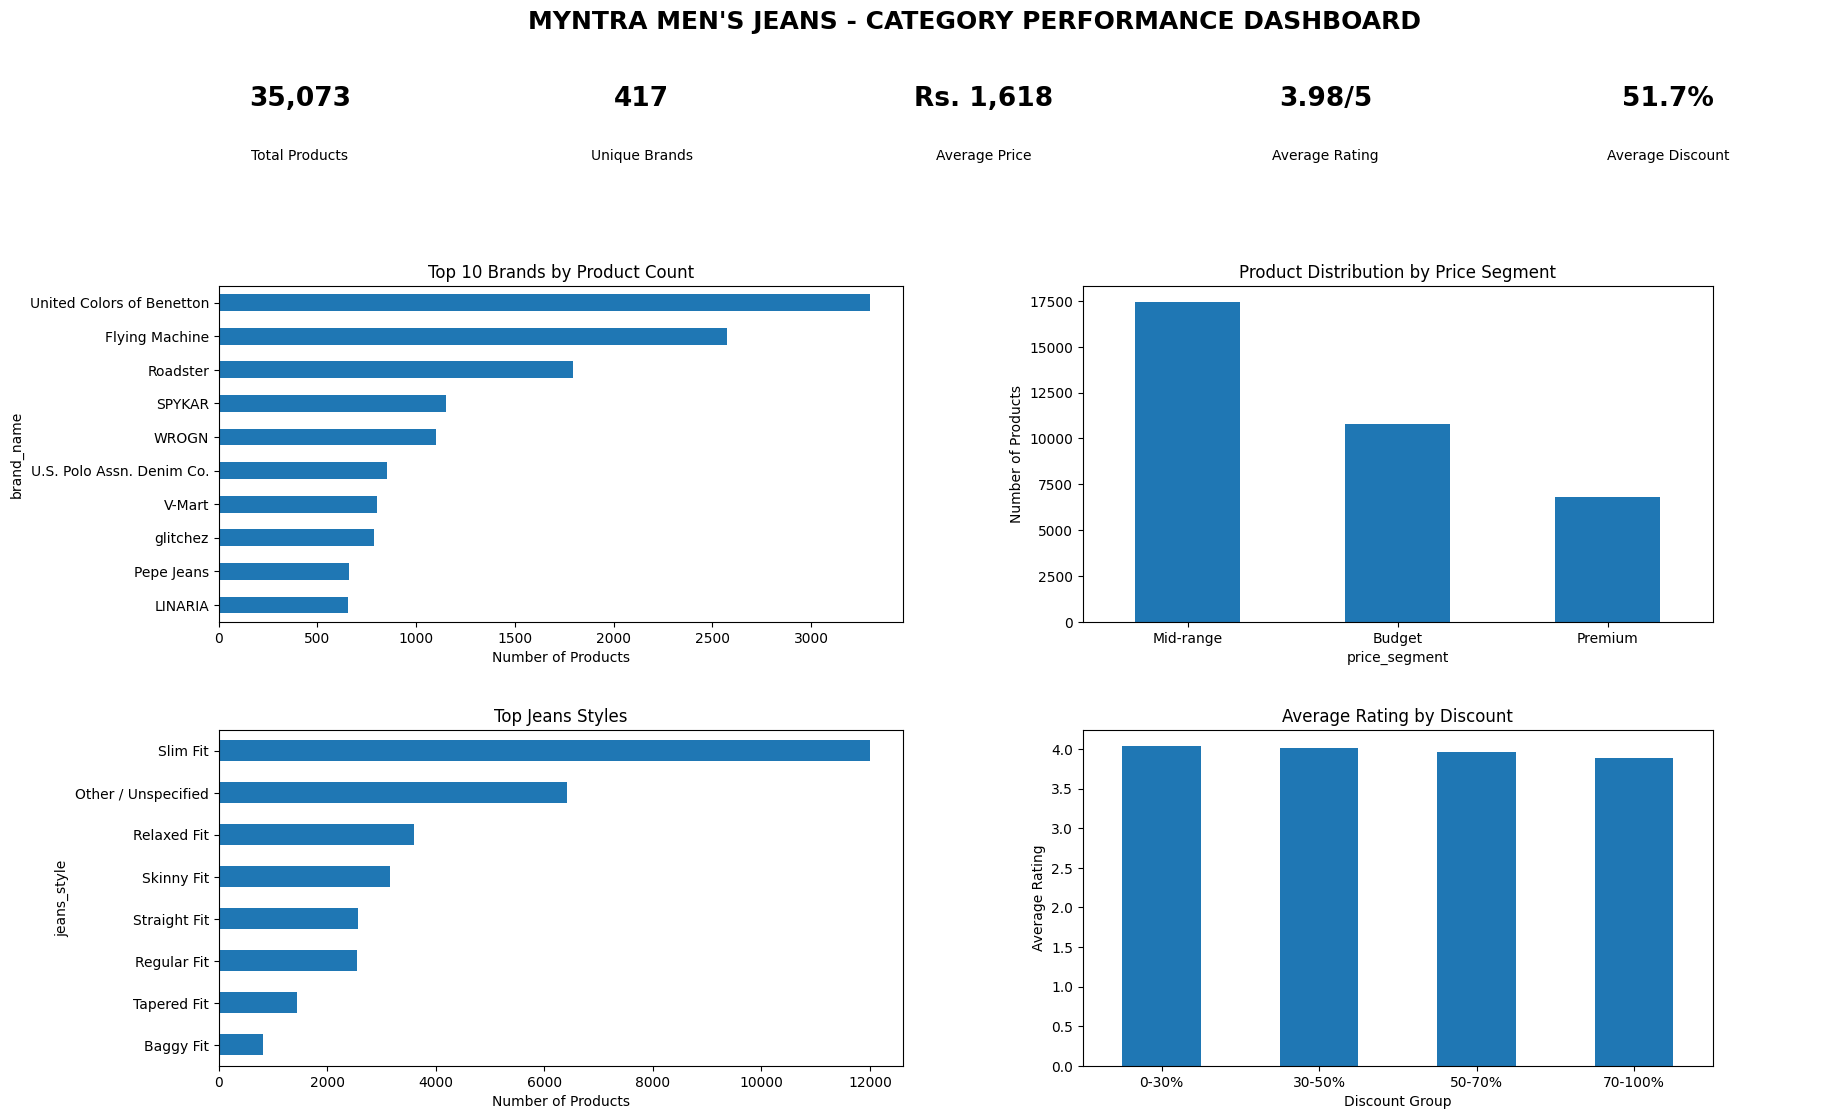

In [19]:

import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# Prepare data
dash = df_clean.copy()

# Create dashboard
fig = plt.figure(figsize=(18, 12))
fig.suptitle(
    "MYNTRA MEN'S JEANS - CATEGORY PERFORMANCE DASHBOARD",
    fontsize=18,
    fontweight='bold'
)

# KPI calculations
total_products = len(dash)
total_brands = dash['brand_name'].nunique()
avg_price = dash['price'].mean()
avg_rating = dash['ratings'].mean()
avg_discount = dash['calculated_discount'].mean()

# KPI cards
kpis = [
    ("Total Products", f"{total_products:,}"),
    ("Unique Brands", f"{total_brands:,}"),
    ("Average Price", f"Rs. {avg_price:,.0f}"),
    ("Average Rating", f"{avg_rating:.2f}/5"),
    ("Average Discount", f"{avg_discount:.1f}%")
]

for i, (label, value) in enumerate(kpis):
    ax = fig.add_axes([0.04 + i*0.19, 0.83, 0.17, 0.10])
    ax.axis('off')
    ax.text(0.5, 0.7, value, ha='center',
            fontsize=19, fontweight='bold')
    ax.text(0.5, 0.25, label, ha='center',
            fontsize=10)

# Brand performance
brand_data = (
    dash.groupby('brand_name')
    .size()
    .sort_values(ascending=False)
    .head(10)
    .sort_values()
)

ax1 = fig.add_axes([0.08, 0.47, 0.38, 0.28])
brand_data.plot(kind='barh', ax=ax1)
ax1.set_title("Top 10 Brands by Product Count")
ax1.set_xlabel("Number of Products")

# Price segment
ax2 = fig.add_axes([0.56, 0.47, 0.35, 0.28])
segment_data = dash['price_segment'].value_counts()
segment_data.plot(kind='bar', ax=ax2)
ax2.set_title("Product Distribution by Price Segment")
ax2.set_ylabel("Number of Products")
ax2.tick_params(axis='x', rotation=0)

# Jeans style
ax3 = fig.add_axes([0.08, 0.10, 0.38, 0.28])
style_data = (
    dash['jeans_style'].value_counts().head(8)
    .sort_values()
)
style_data.plot(kind='barh', ax=ax3)
ax3.set_title("Top Jeans Styles")
ax3.set_xlabel("Number of Products")

# Discount vs rating
ax4 = fig.add_axes([0.56, 0.10, 0.35, 0.28])

discount_rating = dash.groupby(
    pd.cut(
        dash['calculated_discount'],
        bins=[0, 30, 50, 70, 100],
        labels=['0-30%', '30-50%', '50-70%', '70-100%']
    ),
    observed=False
)['ratings'].mean()

discount_rating.plot(kind='bar', ax=ax4)
ax4.set_title("Average Rating by Discount")
ax4.set_ylabel("Average Rating")
ax4.set_xlabel("Discount Group")
ax4.tick_params(axis='x', rotation=0)

plt.show()


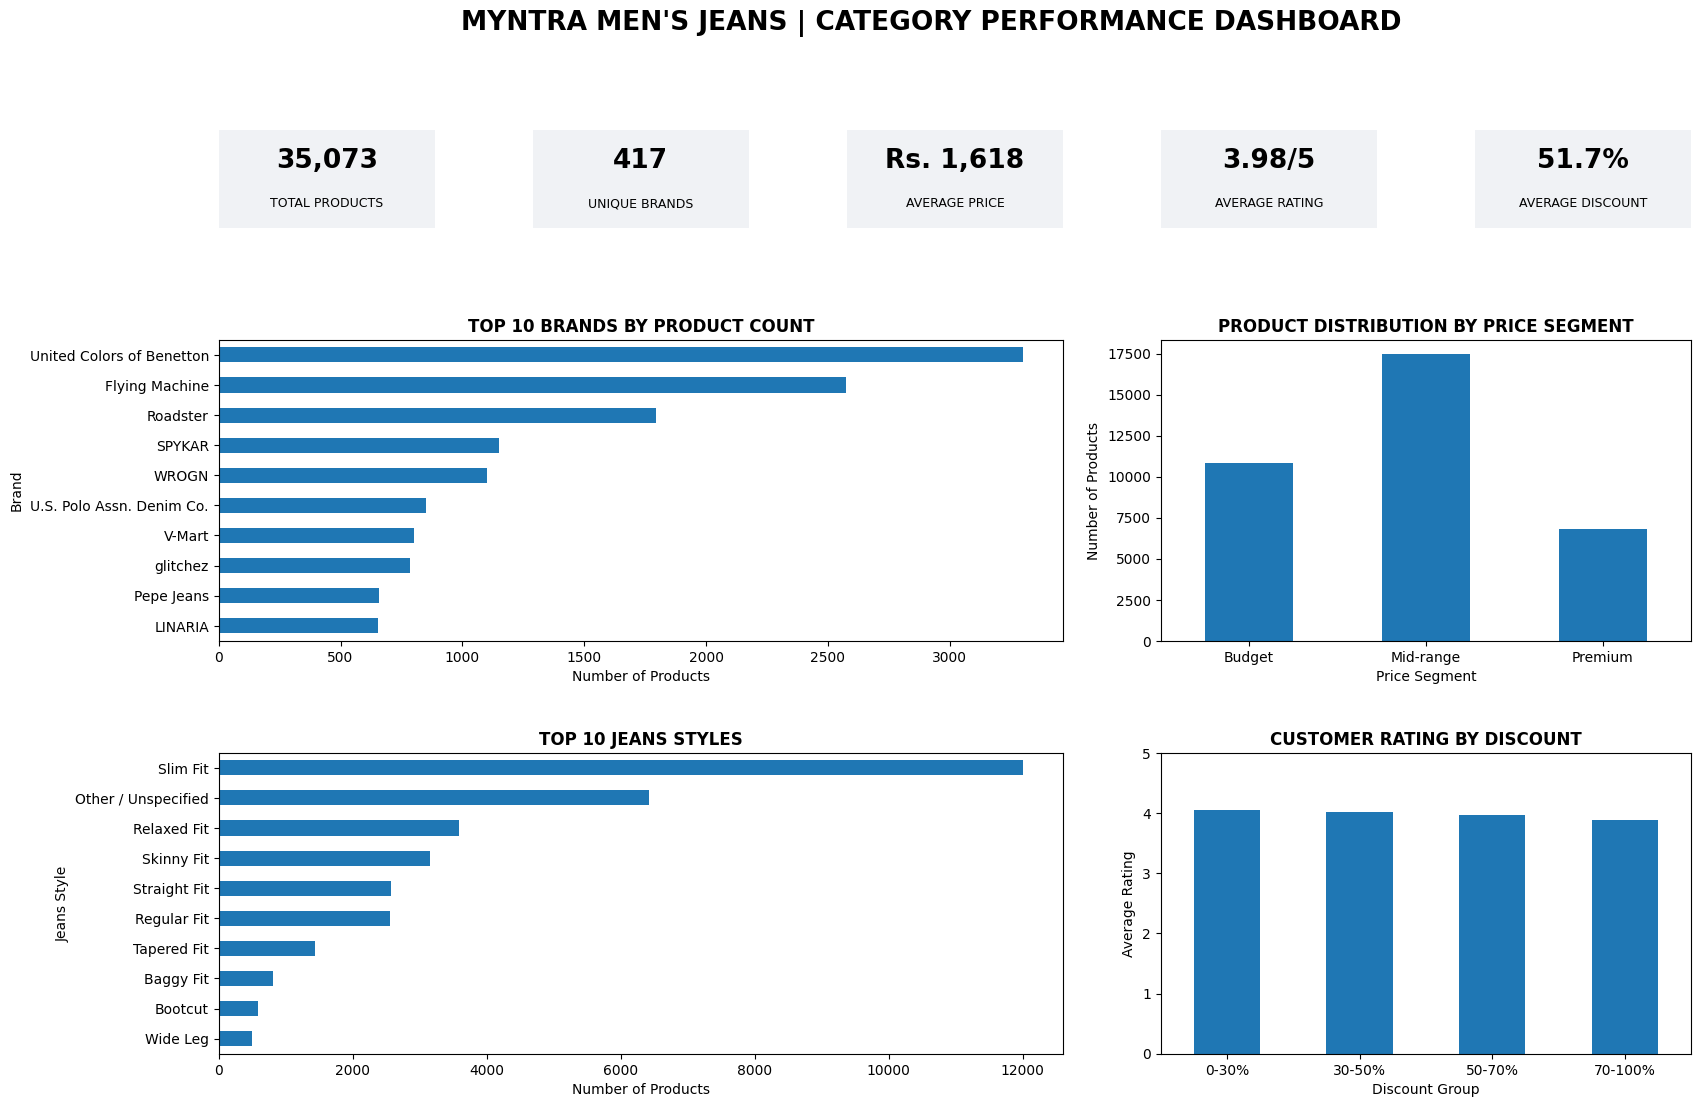


DASHBOARD GENERATED SUCCESSFULLY!
Total Products: 35,073
Unique Brands: 417


In [20]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Prepare dataset
dash = df_clean.copy()

# Calculate KPIs
kpis = [
    ("TOTAL PRODUCTS", f"{len(dash):,}"),
    ("UNIQUE BRANDS", f"{dash['brand_name'].nunique():,}"),
    ("AVERAGE PRICE", f"Rs. {dash['price'].mean():,.0f}"),
    ("AVERAGE RATING", f"{dash['ratings'].mean():.2f}/5"),
    ("AVERAGE DISCOUNT", f"{dash['calculated_discount'].mean():.1f}%")
]

# Create dashboard layout
fig = plt.figure(figsize=(19, 12))
gs = fig.add_gridspec(
    3, 5,
    height_ratios=[0.75, 2.3, 2.3],
    hspace=0.48,
    wspace=0.45
)

fig.suptitle(
    "MYNTRA MEN'S JEANS | CATEGORY PERFORMANCE DASHBOARD",
    fontsize=19,
    fontweight='bold',
    y=0.98
)

# KPI cards
for i, (label, value) in enumerate(kpis):
    ax = fig.add_subplot(gs[0, i])
    ax.set_facecolor('#F0F2F5')
    ax.set_xticks([])
    ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_visible(False)

    ax.text(
        0.5, 0.68, value,
        ha='center', va='center',
        fontsize=19, fontweight='bold'
    )
    ax.text(
        0.5, 0.25, label,
        ha='center', va='center',
        fontsize=9
    )

# 1. Top brands
ax1 = fig.add_subplot(gs[1, :3])

brand_data = (
    dash.groupby('brand_name')
    .size()
    .nlargest(10)
    .sort_values()
)

brand_data.plot(kind='barh', ax=ax1)
ax1.set_title("TOP 10 BRANDS BY PRODUCT COUNT", fontweight='bold')
ax1.set_xlabel("Number of Products")
ax1.set_ylabel("Brand")

# 2. Price segment
ax2 = fig.add_subplot(gs[1, 3:])

segment_data = (
    dash['price_segment']
    .value_counts()
    .reindex(['Budget', 'Mid-range', 'Premium'])
    .dropna()
)

segment_data.plot(kind='bar', ax=ax2)
ax2.set_title("PRODUCT DISTRIBUTION BY PRICE SEGMENT",
              fontweight='bold')
ax2.set_ylabel("Number of Products")
ax2.set_xlabel("Price Segment")
ax2.tick_params(axis='x', rotation=0)

# 3. Jeans styles
ax3 = fig.add_subplot(gs[2, :3])

style_data = (
    dash['jeans_style']
    .value_counts()
    .head(10)
    .sort_values()
)

style_data.plot(kind='barh', ax=ax3)
ax3.set_title("TOP 10 JEANS STYLES", fontweight='bold')
ax3.set_xlabel("Number of Products")
ax3.set_ylabel("Jeans Style")

# 4. Discount vs rating
ax4 = fig.add_subplot(gs[2, 3:])

discount_groups = pd.cut(
    dash['calculated_discount'],
    bins=[0, 30, 50, 70, 100],
    labels=['0-30%', '30-50%', '50-70%', '70-100%']
)

rating_data = (
    dash.groupby(discount_groups, observed=False)['ratings']
    .mean()
)

rating_data.plot(kind='bar', ax=ax4)
ax4.set_title("CUSTOMER RATING BY DISCOUNT",
              fontweight='bold')
ax4.set_xlabel("Discount Group")
ax4.set_ylabel("Average Rating")
ax4.set_ylim(0, 5)
ax4.tick_params(axis='x', rotation=0)

# Final formatting
plt.savefig(
    'Myntra_Category_Dashboard.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

print("\nDASHBOARD GENERATED SUCCESSFULLY!")
print("Total Products:", f"{len(dash):,}")
print("Unique Brands:", dash['brand_name'].nunique())
